# Buổi C5: Cây quyết định, trò chơi hai mươi câu hỏi

**Hiện trường.** Chị Hạnh quay lại với dữ liệu sàng lọc tế bào u (C2). Lần này chị không cần mô hình tốt nhất, mà cần **một tờ quy tắc** có thể in ra dán ở phòng xét nghiệm, để điều dưỡng làm theo từng bước mà **không cần máy tính**: *"đo chu vi nhân, nếu lớn hơn bao nhiêu thì hỏi tiếp câu này..."*

Mô hình sinh ra cho việc đó là **cây quyết định**: một chuỗi câu hỏi **có/không** dẫn dần đến kết luận, giống trò chơi *đoán đồ vật bằng hai mươi câu hỏi*.

**Câu hỏi của buổi này:** *máy chọn câu hỏi nào để hỏi trước, hỏi đến đâu thì dừng, và tờ quy tắc đó đáng tin đến đâu?*

**Mindset của người làm dữ liệu:** có những mô hình được chọn vì **giải thích được**, không vì chính xác nhất. Cây là ví dụ điển hình: ta thường đánh đổi một chút độ đúng để lấy một bộ quy tắc người đọc được.

**Lưu ý:** dữ liệu mẫu để học, **không dùng để chẩn đoán**. Buổi này dùng lại cú pháp từ A1 đến C4; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Cây đọc như tờ quy tắc: nút, nhánh, lá |
| Chặng 2 | Máy chọn câu hỏi thế nào: độ lẫn (Gini) và quét ngưỡng |
| Chặng 3 | `DecisionTreeClassifier`: hồ sơ, độ quan trọng của cột, không cần chuẩn hóa |
| Chặng 4 | Cây mọc quá cao thì quá khớp: `max_depth` và `min_samples_leaf` |
| Chặng 5 | Cây bấp bênh: đổi vài ca, đổi cả cây |
| Chặng 6 | Giới hạn: ranh giới chéo và phán quyết |

## Chặng 1: Cây đọc như tờ quy tắc, nút, nhánh, lá

**Câu hỏi:** một cây quyết định trông ra sao và đọc thế nào?

Ta cho máy học một cây **thật thấp** (chỉ tối đa 2 tầng câu hỏi) để đọc được hết bằng mắt.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
bc = load_breast_cancer(as_frame=True)
X = bc.data
y = 1 - bc.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
tree2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
print(export_text(tree2, feature_names=list(X.columns), show_weights=True))
print("accuracy: train", round(tree2.score(X_train, y_train), 3), "| test", round(tree2.score(X_test, y_test), 3))

|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.18
|   |   |--- weights: [257.00, 12.00] class: 0
|   |--- worst concave points >  0.18
|   |   |--- weights: [0.00, 8.00] class: 1
|--- worst perimeter >  112.80
|   |--- mean texture <= 14.95
|   |   |--- weights: [5.00, 2.00] class: 0
|   |--- mean texture >  14.95
|   |   |--- weights: [5.00, 137.00] class: 1

accuracy: train 0.955 | test 0.895


**Giải thích từng dòng**

- `from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree`: **mới:** module `sklearn.tree`: `DecisionTreeClassifier` là cây phân loại; `export_text` in cây thành **chữ**; `plot_tree` vẽ cây thành **hình**.
- `bc = load_breast_cancer(...); y = 1 - bc.target`: (đã học ở C2) tế bào u, nhóm dương 1 là **ác tính**.
- `DecisionTreeClassifier(max_depth=2, random_state=0)`: `max_depth=2`: tối đa **hai tầng** câu hỏi. `random_state=0`: khi hai câu hỏi tốt ngang nhau, máy chọn ngẫu nhiên; hạt giống cố định cho kết quả lặp lại được.
- `.fit(X_train, y_train)`: máy **thử rất nhiều câu hỏi** và giữ câu hỏi tốt nhất ở mỗi bước (chặng 2 nói chi tiết).
- `export_text(tree2, feature_names=list(X.columns), show_weights=True)`: in cây thành các dòng thụt lề: mỗi dòng bắt đầu bằng `|---` là một câu hỏi hoặc một kết luận. `feature_names` để in tên cột thay vì `feature_0`; `show_weights=True` in thêm **số ca mỗi nhóm** ở mỗi lá.

**Cách đọc.** Đọc từ trên xuống, như một tờ quy tắc:

1. **Câu hỏi đầu:** *chu vi nhân tế bào tệ nhất (`worst perimeter`) có ≤ 112,8 không?*
2. Nếu **có** (nhánh trên): hỏi tiếp *`worst concave points` ≤ 0,18 không?* Có thì kết luận **lành** (lá "[257, 12]": 257 ca lành, 12 ca ác ở lá này); không thì kết luận **ác** (lá "[0, 8]": 8 ca ác, 0 ca lành).
3. Nếu **không** (nhánh dưới): hỏi *`mean texture` ≤ 14,95 không?* Có thì **lành** (lá [5, 2], sát nhau), không thì **ác** (lá [5, 137]).

- **Con số:** cây hai tầng đạt **0,955** trên tập học và **0,895** trên tập thi (so với 0,63 của máy lười). Mô hình này chỉ cần bốn lá, ba loại số đo.
- **Thuật ngữ:** câu hỏi gọi là **nút** (node); nút đầu tiên là **gốc** (root); chỗ dừng và kết luận gọi là **lá** (leaf); đường nối là **nhánh**. Số tầng là **độ sâu** (depth).
- **Ý nghĩa:** đây chính là thứ chị Hạnh muốn: *tờ quy tắc đọc được, không cần máy tính*. Lá "[0, 8]" có nghĩa "tám ca rơi vào đây đều là ác"; lá "[257, 12]" nhắc: *"cái lá 'lành' này vẫn lẫn 12 ca ác"*, nên những ca bị xếp vào đó không phải chắc chắn lành.

Xem cùng cây ấy dưới dạng hình (mỗi ô có thêm vài con số):

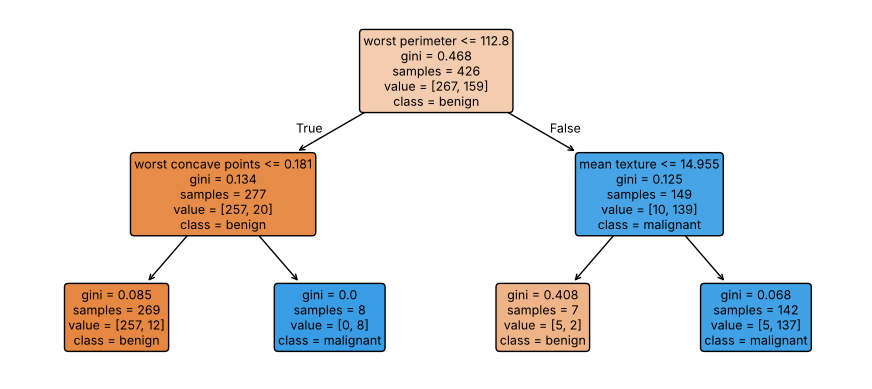

 worst perimeter  worst concave points  mean texture
           151.7                  0.18          24.8
tree says: malignant | predict_proba: [0.035 0.965] | truth: malignant


In [3]:
plt.figure(figsize=(11, 4.8))
plot_tree(tree2, feature_names=list(X.columns), class_names=["benign", "malignant"], filled=True, impurity=True, rounded=True, fontsize=9, proportion=False)
plt.show()
patient = X_test.iloc[[0]]
print(patient[["worst perimeter", "worst concave points", "mean texture"]].round(2).to_string(index=False))
print("tree says:", ["benign", "malignant"][int(tree2.predict(patient)[0])], "| predict_proba:", tree2.predict_proba(patient).round(3)[0], "| truth:", ["benign", "malignant"][int(y_test.iloc[0])])

**Giải thích từng dòng**

- `plot_tree(tree2, ..., filled=True, impurity=True, rounded=True, ...)`: **mới:** vẽ cây. `class_names` đặt tên hai nhóm theo thứ tự nhãn 0, 1. `filled=True` tô màu ô theo nhóm chiếm đa số (đậm hơn nghĩa là *thuần hơn*). `impurity=True` in **gini** của nút (độ lẫn, chặng 2). Mỗi ô ghi: câu hỏi, gini, số mẫu (`samples`), số ca mỗi nhóm (`value`), nhóm kết luận (`class`).
- `patient = X_test.iloc[[0]]`: (đã học `iloc`) bệnh nhân thi đầu tiên; hai lớp ngoặc vuông giữ dạng **bảng một dòng** (sklearn đòi bảng).
- `tree2.predict_proba(patient)`: xác suất = **tỉ lệ nhóm ở lá mà ca này rơi vào**. Với lá [5, 137] thì xác suất ác là 137/142 = 0,965.

**Cách đọc**

- **Bức tranh:** màu **cam** là nhóm lành, màu **xanh** là nhóm ác; màu càng đậm thì nút càng thuần. Ô gốc (trên cùng) chỉ cam **nhạt** vì lẫn nhiều (gini 0,468); các ô dưới đậm hơn: lá "[0, 8]" xanh đậm nhất (gini 0), lá "[257, 12]" cam đậm. Mỗi lần đi xuống, các ô **thuần hơn**: mỗi câu hỏi làm nhóm bớt lẫn.
- **Con số:** bệnh nhân đầu tiên có `worst perimeter` = 151,7, `worst concave points` = 0,18. Cây trả lời **ác**, xác suất ác **0,965**, thực tế là **ác**.
- **Ý nghĩa của `predict_proba` ở cây:** chỉ là **tỉ lệ nhóm trong lá** của các ca tập học. Vì vậy xác suất của cây rất thô (chỉ có bấy nhiêu giá trị khác nhau, bằng số lá).

**Mang về chặng 1:** cây = chuỗi câu hỏi có/không; gốc, nút, nhánh, lá, độ sâu; đọc `export_text` hoặc `plot_tree` là đọc được **tờ quy tắc**. Xác suất của cây là tỉ lệ nhóm trong lá.

## Chặng 2: Máy chọn câu hỏi thế nào, độ lẫn (Gini) và quét ngưỡng

**Câu hỏi:** trong 30 cột và hàng trăm ngưỡng có thể, vì sao máy chọn đúng "`worst perimeter` ≤ 112,8" làm câu hỏi đầu?

Ta cần thước đo **độ lẫn** của một nhóm. Cây dùng **chỉ số Gini**:

**Gini = 1 − (tỉ lệ ác)² − (tỉ lệ lành)²**

Nhóm toàn ác hoặc toàn lành thì Gini = 0 (thuần). Nhóm một nửa một nửa thì Gini = 0,5 (lẫn nhất).

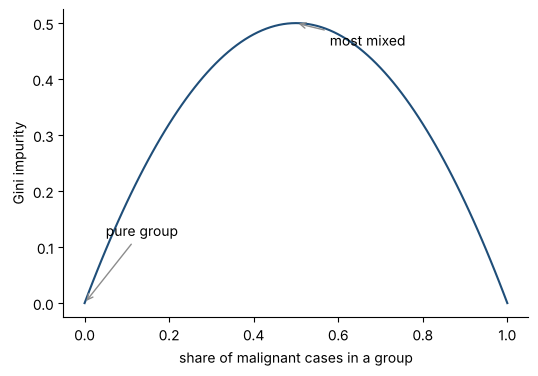

root node:  267 benign, 159 malignant -> Gini = 0.468


In [4]:
p = np.linspace(0, 1, 101)
plt.plot(p, 1 - p ** 2 - (1 - p) ** 2, color=BLUE)
plt.xlabel("share of malignant cases in a group"); plt.ylabel("Gini impurity")
plt.annotate("pure group", (0, 0), xytext=(0.05, 0.12), arrowprops=dict(arrowstyle="->", color=GRAY))
plt.annotate("most mixed", (0.5, 0.5), xytext=(0.58, 0.46), arrowprops=dict(arrowstyle="->", color=GRAY))
plt.show()

def gini(labels):
    share = np.mean(labels)
    return 1 - share ** 2 - (1 - share) ** 2

print("root node: ", int((y_train == 0).sum()), "benign,", int((y_train == 1).sum()), "malignant -> Gini =", round(gini(y_train), 3))

**Giải thích từng dòng**

- `p = np.linspace(0, 1, 101)`: tỉ lệ ác từ 0 đến 1 (nhóm nào cũng nằm đâu đó trên đường này).
- `1 - p ** 2 - (1 - p) ** 2`: công thức Gini cho hai nhóm: hình **cái vòm**, đáy hai đầu bằng 0, đỉnh 0,5 ở giữa.
- `plt.annotate("pure group", (0, 0), xytext=(...), arrowprops=...)`: (đã học ở C2) ghi chú kèm mũi tên.
- `def gini(labels):`: gói công thức thành hàm: nhận danh sách nhãn 0/1, trả độ lẫn. `np.mean(labels)` là tỉ lệ nhãn 1 (ác), vì trung bình của dãy 0/1 chính là tỉ lệ số 1.

**Cách đọc:** nhóm gốc có 267 ca lành và 159 ca ác, Gini = **0,468** (khá lẫn). Mục tiêu của mỗi câu hỏi là **chia nhóm thành hai nhóm con thuần hơn**. Cách chấm một câu hỏi: tính Gini của hai nhóm con rồi lấy **trung bình có trọng số theo số ca** (nhóm con đông thì tiếng nói nặng hơn). Câu hỏi nào cho **Gini trung bình thấp nhất** thì thắng.

Ta tự làm lại việc máy làm, cho riêng cột `worst perimeter`: thử mọi ngưỡng.

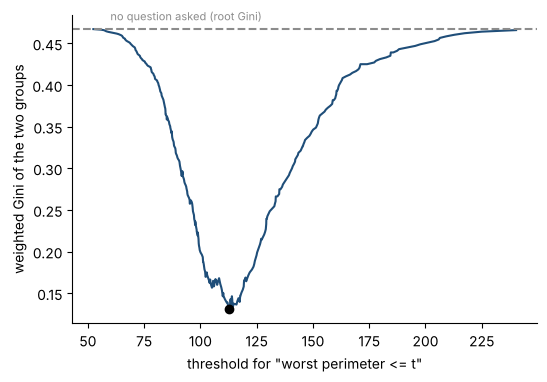

best threshold: 112.80 | weighted Gini there: 0.131 (root was 0.468)
tree2 chose   : 112.8 on worst perimeter


In [5]:
def best_threshold(values, labels):
    order = np.argsort(values)
    v, l = np.asarray(values)[order], np.asarray(labels)[order]
    cuts = (v[:-1] + v[1:]) / 2
    scores = []
    for cut in cuts:
        left, right = l[v <= cut], l[v > cut]
        if len(left) == 0 or len(right) == 0:
            scores.append(np.nan); continue
        scores.append((len(left) * gini(left) + len(right) * gini(right)) / len(l))
    scores = np.array(scores)
    return cuts, scores

cuts, scores = best_threshold(X_train["worst perimeter"], y_train)
best_cut = cuts[np.nanargmin(scores)]
plt.plot(cuts, scores, color=BLUE)
plt.plot(best_cut, np.nanmin(scores), "o", color="black")
plt.axhline(gini(y_train), color=GRAY, linestyle="--"); plt.text(60, gini(y_train) + 0.01, "no question asked (root Gini)", fontsize=8, color=GRAY)
plt.xlabel('threshold for "worst perimeter <= t"'); plt.ylabel("weighted Gini of the two groups"); plt.show()
print(f"best threshold: {best_cut:.2f} | weighted Gini there: {np.nanmin(scores):.3f} (root was {gini(y_train):.3f})")
print("tree2 chose   :", round(tree2.tree_.threshold[0], 2), "on", X.columns[tree2.tree_.feature[0]])

**Giải thích từng dòng**

- `def best_threshold(values, labels):`: hàm thử mọi ngưỡng cho một cột.
- `order = np.argsort(values)`: (đã học `argsort` ở C3) thứ tự sắp xếp các giá trị từ nhỏ đến lớn.
- `cuts = (v[:-1] + v[1:]) / 2`: **ngưỡng ứng viên** là điểm giữa hai giá trị liền nhau: `v[:-1]` là mọi giá trị trừ cái cuối, `v[1:]` là mọi giá trị trừ cái đầu; cộng từng cặp rồi chia đôi.
- `left, right = l[v <= cut], l[v > cut]`: chia các ca thành hai nhóm: giá trị ≤ ngưỡng đi **nhánh trái**, còn lại đi **nhánh phải**.
- `scores.append((len(left) * gini(left) + len(right) * gini(right)) / len(l))`: **Gini trung bình có trọng số** của hai nhóm con: mỗi nhóm nhân với số ca của nó, chia cho tổng số ca.
- `np.nanargmin(scores)`: như `argmin` nhưng **bỏ qua `NaN`** (có khi một nhóm rỗng nên ta đánh dấu `NaN`).
- `tree2.tree_.threshold[0], tree2.tree_.feature[0]`: **mới:** `tree_` là cấu trúc bên trong của cây đã học; `.threshold[0]` và `.feature[0]` là ngưỡng và chỉ số cột của **nút 0 (gốc)**. Để so với kết quả tự làm.

**Cách đọc**

- **Con số:** ngưỡng tốt nhất ta tìm ra là **112,80**, khớp với ngưỡng cây chọn (**112,80**, cột `worst perimeter`). Gini trung bình giảm từ **0,468** (chưa hỏi gì) xuống **0,131** chỉ với *một câu hỏi*.
- **Bức tranh:** đường cong có hình **cái bát** với đáy khá sâu: ngưỡng quá thấp thì dồn gần hết ca về một phía (không chia được gì); quá cao cũng vậy; ở giữa (khoảng 100 đến 115) hai nhóm con thuần nhất.
- **Ý nghĩa:** cây **không nghĩ**, nó **thử hết**. Tại mỗi nút, máy làm đúng việc ta vừa làm *cho cả 30 cột*, chọn cặp (cột, ngưỡng) có Gini trung bình thấp nhất, rồi **lặp lại** trên từng nhóm con cho đến khi dừng. Đó là lý do cây gọi là thuật toán **tham lam** (greedy): mỗi bước chọn tốt nhất *ngay lúc đó*, không nhìn xa.

**Mang về chặng 2:** cây chọn câu hỏi làm **Gini trung bình có trọng số** của hai nhóm con thấp nhất, thử mọi cột và mọi ngưỡng, rồi lặp lại trên từng nhánh.

## Chặng 3: `DecisionTreeClassifier`, hồ sơ, độ quan trọng của cột, không cần chuẩn hóa

**Câu hỏi:** nếu không giới hạn độ sâu thì sao, và cột nào quan trọng nhất?

full tree: depth = 8 | leaves = 21 | train accuracy = 1.0 | test accuracy = 0.937


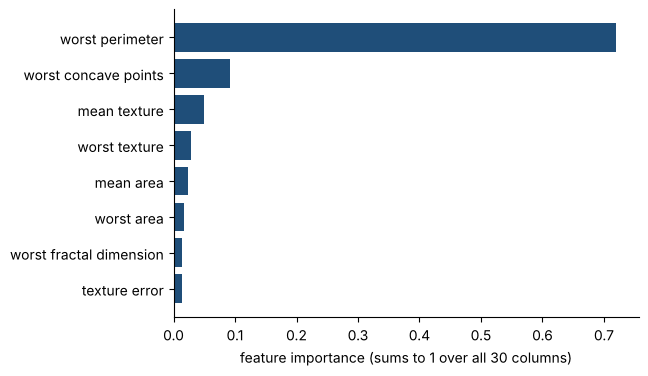

columns with importance 0: 15 of 30


In [6]:
tree_full = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("full tree: depth =", tree_full.get_depth(), "| leaves =", tree_full.get_n_leaves(), "| train accuracy =", round(tree_full.score(X_train, y_train), 3), "| test accuracy =", round(tree_full.score(X_test, y_test), 3))
importance = pd.Series(tree_full.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importance.head(8)[::-1]
plt.barh(top.index, top.values, color=BLUE)
plt.xlabel("feature importance (sums to 1 over all 30 columns)"); plt.show()
print("columns with importance 0:", int((importance == 0).sum()), "of", len(importance))

**Giải thích từng dòng**

- `DecisionTreeClassifier(random_state=0)`: không đặt `max_depth`: cây **mọc cho đến khi mọi lá thuần** (hoặc không chia được nữa).
- `tree_full.get_depth(), tree_full.get_n_leaves()`: độ sâu và số lá của cây đã mọc.
- `tree_full.feature_importances_`: **mới:** **độ quan trọng của từng cột**: mỗi lần cột đó được dùng để chia, nó "ghi công" bằng mức *giảm Gini* mang lại (nhân số ca); cộng lại rồi chia để tổng bằng 1. Cột chưa bao giờ được dùng có độ quan trọng 0.
- `importance.head(8)[::-1]`: lấy tám cột đầu rồi **đảo ngược** (`[::-1]`) để `barh` vẽ cột quan trọng nhất ở trên cùng.

**Cách đọc**

- **Con số:** cây không giới hạn mọc tới **8 tầng, 21 lá**, đạt **1,000 trên tập học** (thuộc lòng từng ca) và **0,937 trên tập thi**. Cột `worst perimeter` chiếm **72%** tổng độ quan trọng; 15 trong 30 cột có độ quan trọng 0 (không được dùng lần nào).
- **Bức tranh:** thanh đầu vượt trội, các thanh sau ngắn dần: cây dựa chủ yếu vào *một cột* và vài cột phụ. Độ chênh giữa điểm học (gần 1,0) và điểm thi (thấp hơn) là dấu hiệu của **quá khớp** (chặng 4).
- **Cẩn thận khi đọc độ quan trọng:** nó nói *cột nào cây đã dùng nhiều*, không nói *cột nào gây ra bệnh*. Các cột `worst perimeter`, `worst radius`, `worst area` gần như là *cùng một thứ đo* (nhân tế bào lớn); cây chọn một trong số chúng gần như ngẫu nhiên, và các cột còn lại bị "mất công". Hệ quả: độ quan trọng **bị chia lẻ** giữa các cột tương quan.

**Hồ sơ của mô hình:**

| Mục | `DecisionTreeClassifier` |
|---|---|
| **Nó là gì** | Chuỗi câu hỏi có/không chia dữ liệu thành các lá thuần dần |
| **Dùng khi nào** | Cần **quy tắc đọc được**; cột hỗn hợp số và nhóm; quan hệ không tuyến tính |
| **`X`** | Bảng số; **không cần chuẩn hóa** (chỉ so sánh "lớn hơn ngưỡng", không đo khoảng cách) |
| **`y`** | Nhãn nhóm |
| **Ô trống `NaN` trong `X`** | Bản sklearn **từ 1.3 trở lên** cho cây tự xử lý `NaN` (đưa sang nhánh có lợi hơn); bản cũ báo lỗi. Cẩn thận: nên điền hoặc kiểm tra trước, và đừng giả định mọi mô hình khác cũng chịu `NaN` |
| **Module sklearn** | `sklearn.tree.DecisionTreeClassifier` |
| **`fit` / `predict`** | `fit` quét mọi cột, mọi ngưỡng ở từng nút; `predict` đi từ gốc xuống lá; `predict_proba` là tỉ lệ trong lá |
| **Sau `fit` có gì** | `feature_importances_`, `tree_`, `get_depth()`, `get_n_leaves()`; **không** có `coef_`, `intercept_` |
| **Siêu tham số chính** | `max_depth`, `min_samples_leaf`, `min_samples_split`, `ccp_alpha` |

Kiểm chứng điều "không cần chuẩn hóa":

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
tree_scaled = DecisionTreeClassifier(random_state=0).fit(scaler.transform(X_train), y_train)
same = (tree_full.predict(X_test) == tree_scaled.predict(scaler.transform(X_test))).all()
print("same test predictions with and without scaling:", bool(same))

same test predictions with and without scaling: True


**Giải thích từng dòng**

- `scaler = StandardScaler().fit(X_train)`: (đã học) bộ chuẩn hóa học từ tập học.
- `tree_scaled = DecisionTreeClassifier(random_state=0).fit(scaler.transform(X_train), y_train)`: học lại cây trên dữ liệu **đã chuẩn hóa**.
- `(tree_full.predict(X_test) == tree_scaled.predict(scaler.transform(X_test))).all()`: so dự đoán hai cây trên tập thi, từng ca một: `.all()` hỏi "tất cả giống nhau?".

**Cách đọc:** hai cây cho **đúng cùng dự đoán**. Chuẩn hóa chỉ *đổi ngưỡng* (112,8 thành một số khác trên thang mới) mà không đổi *thứ tự các ca*: vị trí chia nhóm không đổi. Đây là điểm tiện lợi của cây so với k-NN (C3), logistic có phạt (C1) hay Ridge (B6): **bỏ qua được bước chuẩn hóa**.

**Mang về chặng 3:** cây không cần chuẩn hóa; `feature_importances_` cho biết cột nào được dùng nhiều (không phải nhân quả, và bị chia lẻ giữa các cột tương quan); cây không giới hạn thuộc lòng tập học.

## Chặng 4: Cây mọc quá cao thì quá khớp, `max_depth` và `min_samples_leaf`

**Câu hỏi:** điểm học 1,000 mà điểm thi thấp hơn: dừng cây ở đâu cho vừa?

Cây không bị giới hạn là ví dụ **quá khớp cực đoan**: nó chia đến khi từng lá chỉ còn vài ca (thậm chí một ca), tức là *học thuộc* cả nhiễu. Ba cách ghìm: `max_depth` (số tầng tối đa), `min_samples_leaf` (mỗi lá phải có tối thiểu bấy nhiêu ca) và `ccp_alpha` (cắt tỉa). Ta quét `max_depth`, đo bằng kiểm định chéo lặp **chỉ trên tập học**:

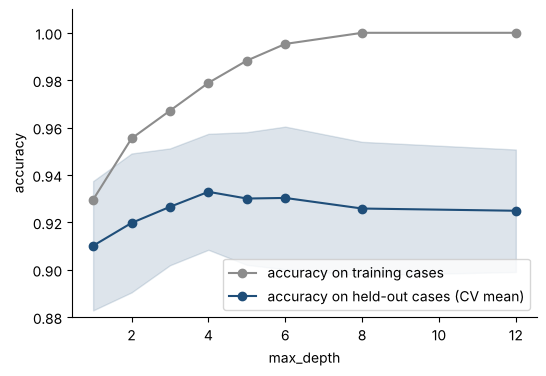

 max_depth  train  CV mean  CV std
         1  0.930    0.910   0.027
         2  0.955    0.920   0.029
         3  0.967    0.927   0.025
         4  0.979    0.933   0.024
         5  0.988    0.930   0.028
         6  0.995    0.930   0.030
         8  1.000    0.926   0.028
        12  1.000    0.925   0.026


In [8]:
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
depths = [1, 2, 3, 4, 5, 6, 8, 12]
cv_mean, cv_std, train_acc = [], [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    s = cross_val_score(m, X_train, y_train, cv=cv)
    cv_mean.append(s.mean()); cv_std.append(s.std()); train_acc.append(m.fit(X_train, y_train).score(X_train, y_train))
cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)
plt.plot(depths, train_acc, "o-", color=GRAY, label="accuracy on training cases")
plt.plot(depths, cv_mean, "o-", color=BLUE, label="accuracy on held-out cases (CV mean)")
plt.fill_between(depths, cv_mean - cv_std, cv_mean + cv_std, color=BLUE, alpha=0.15)
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.ylim(0.88, 1.01); plt.legend(loc="lower right"); plt.show()
print(pd.DataFrame({"max_depth": depths, "train": np.round(train_acc, 3), "CV mean": cv_mean.round(3), "CV std": cv_std.round(3)}).to_string(index=False))

**Giải thích từng dòng**

- `depths = [1, 2, 3, 4, 5, 6, 8, 12]`: các độ sâu thử.
- `DecisionTreeClassifier(max_depth=d, random_state=0)`: mỗi độ sâu một cây.
- `plt.fill_between(...)`: (đã học ở C3) dải dao động của điểm kiểm định chéo.

**Cách đọc**

- **Con số:** điểm trên tập học đi từ **0,930** (một câu hỏi) lên **1,000** (đủ sâu để thuộc lòng). Điểm trên ca chưa gặp lại **đi ngang**: cao nhất ở độ sâu 4 (**0,933**), từ độ sâu 3 đến 12 đều nằm trong khoảng 0,925 đến 0,933; độ lệch chuẩn khoảng 0,025 đến 0,03.
- **Bức tranh:** đường xám (học) leo đều lên sát 1,0; đường xanh (ca chưa gặp) **leo nhanh lúc đầu rồi phẳng hẳn** từ khoảng độ sâu 3 đến 4. Khoảng hở giữa hai đường là **cái giá của việc thuộc lòng**: phần "điểm" thêm vào chỉ để ghi nhớ nhiễu.
- **Ý nghĩa:** thêm tầng quá mức không giúp mà chỉ làm cây **khó đọc hơn** (độ sâu 4 đã 11 lá, độ sâu 8 đã 21 lá). Chọn **độ sâu nhỏ nhất đã đạt cao nguyên**: ở đây 3 hoặc 4. Cùng quy tắc *một độ lệch chuẩn* ở B6: bớt phức tạp khi điểm không khác nhau đáng kể.

Hai núm ghìm khác, so trên cùng kiểm định chéo:

In [9]:
table = {}
for name, m in [("no limit", DecisionTreeClassifier(random_state=0)),
                ("max_depth = 3", DecisionTreeClassifier(max_depth=3, random_state=0)),
                ("min_samples_leaf = 5", DecisionTreeClassifier(min_samples_leaf=5, random_state=0)),
                ("min_samples_leaf = 20", DecisionTreeClassifier(min_samples_leaf=20, random_state=0)),
                ("ccp_alpha = 0.01", DecisionTreeClassifier(ccp_alpha=0.01, random_state=0))]:
    s = cross_val_score(m, X_train, y_train, cv=cv)
    table[name] = {"CV mean": s.mean(), "CV std": s.std(), "leaves (full fit)": m.fit(X_train, y_train).get_n_leaves()}
print(pd.DataFrame(table).T.round(3).to_string())

                       CV mean  CV std  leaves (full fit)
no limit                 0.925   0.026               21.0
max_depth = 3            0.927   0.025                7.0
min_samples_leaf = 5     0.929   0.024               14.0
min_samples_leaf = 20    0.910   0.029                6.0
ccp_alpha = 0.01         0.926   0.021                5.0


**Giải thích từng dòng**

- `min_samples_leaf=5`: **mới:** không cho lá nào có **ít hơn 5 ca**: ép máy dừng chia khi nhóm quá nhỏ. Hiệu quả tương tự `max_depth` nhưng thích nghi theo từng nhánh (nhánh nhiều ca mọc sâu hơn, nhánh ít ca dừng sớm).
- `ccp_alpha=0.01`: **mới:** *cắt tỉa theo chi phí-độ phức tạp* (cost-complexity pruning): cây mọc đủ rồi **cắt những nhánh** mang lại ít lợi hơn `ccp_alpha` mỗi lá. Giống `alpha` của Ridge (B6): số lớn thì cắt mạnh.
- `"leaves (full fit)": m.fit(X_train, y_train).get_n_leaves()`: số lá của cây khi học trên toàn tập học: đo độ phức tạp của cây.

**Cách đọc:** cây không giới hạn có **21 lá** và điểm 0,925; cây ghìm bằng `max_depth = 3` còn **7 lá** mà điểm 0,927; `min_samples_leaf = 5` cho 0,929 với 14 lá; `min_samples_leaf = 20` hơi quá tay (điểm 0,910). Chênh lệch giữa các cách ghìm (0,00 đến 0,01) **nhỏ hơn độ lệch chuẩn** nên chọn cách nào cũng được; cái chắc chắn là *cây ngắn hơn, đọc dễ hơn, không kém* cây thuộc lòng.

Ranh giới của cây trông thế nào? Dùng lại hai cột cánh hoa của chị Mai (C1), **ba loài** (có thêm loài setosa):

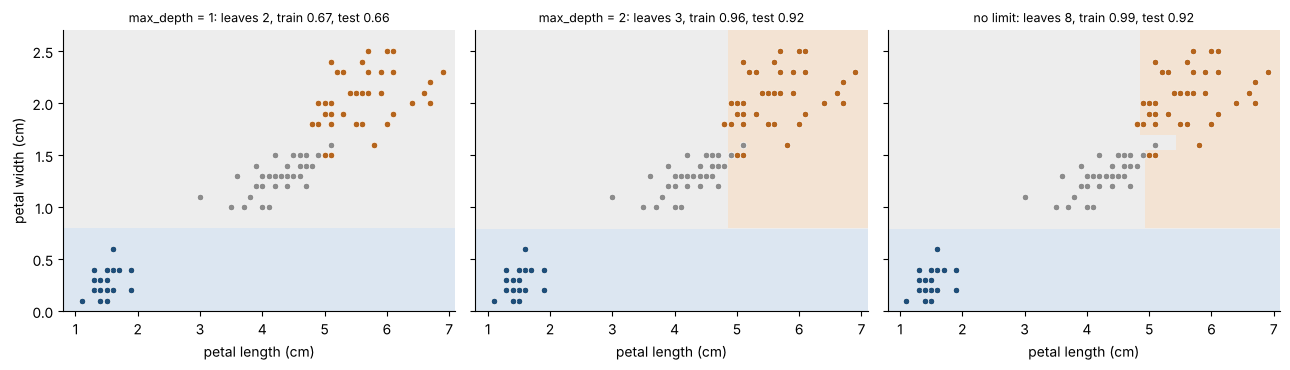

In [10]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
Xi = iris.data[["petal length (cm)", "petal width (cm)"]]
yi = iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.25, random_state=42, stratify=yi)
palette = {0: BLUE, 1: GRAY, 2: "#B5651D"}
def draw_tree_map(depth, ax):
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xi_train, yi_train)
    xx, yy = np.meshgrid(np.linspace(0.8, 7.1, 300), np.linspace(0, 2.7, 300))
    zone = m.predict(pd.DataFrame({"petal length (cm)": xx.ravel(), "petal width (cm)": yy.ravel()})).reshape(xx.shape)
    ax.contourf(xx, yy, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#DCE6F1", "#EDEDED", "#F3E3D3"])
    for cls in [0, 1, 2]:
        mask = (yi_train == cls).values
        ax.scatter(Xi_train.iloc[mask, 0], Xi_train.iloc[mask, 1], color=palette[cls], s=22, edgecolor="white", linewidth=0.5)
    label = "no limit" if depth is None else f"max_depth = {depth}"
    ax.set_title(f"{label}: leaves {m.get_n_leaves()}, train {m.score(Xi_train, yi_train):.2f}, test {m.score(Xi_test, yi_test):.2f}", fontsize=9)
    ax.set_xlabel("petal length (cm)")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, d in zip(axes, [1, 2, None]):
    draw_tree_map(d, ax)
axes[0].set_ylabel("petal width (cm)")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `Xi = iris.data[["petal length (cm)", "petal width (cm)"]]`: hai cột cánh hoa của cả **ba loài** (150 cây).
- `def draw_tree_map(depth, ax):`: hàm vẽ bản đồ vùng đoán của cây theo độ sâu (giống `draw_knn_map` ở C3).
- `m.predict(pd.DataFrame({...}))`: bảng điểm lưới có đúng **tên cột như lúc học** để sklearn không phàn nàn.
- `label = "no limit" if depth is None else f"max_depth = {depth}"`: `depth is None` kiểm tra "không giới hạn"; một dòng `if ... else ...` chọn chữ cho tiêu đề.
- `for ax, d in zip(axes, [1, 2, None]):`: ba khung: một câu hỏi, hai tầng, không giới hạn.

**Cách đọc**

- **Con số:** cây một tầng chỉ có 2 lá (không phân biệt nổi hai loài còn lại); cây hai tầng có 3 lá; cây không giới hạn có 8 lá.
- **Bức tranh:** ranh giới của cây luôn là các **hình chữ nhật** ghép lại, vì mỗi câu hỏi chỉ cắt *theo một cột* ("petal width ≤ 0,8?") nên đường cắt luôn **song song với trục**. Cây một tầng cắt đúng một đường; hai tầng cho ba vùng chữ nhật; cây không giới hạn thêm vài vùng nhỏ ôm lấy các điểm lẻ.
- **So với logistic (C1) và k-NN (C3):** đường biên của logistic là *đường thẳng nghiêng*, của k-NN là *đường cong trơn*, của cây là *đường gấp khúc vuông góc*. Mỗi mô hình có "chữ viết" riêng.

**Mang về chặng 4:** cây không giới hạn thuộc lòng (điểm học 1,0). Ghìm bằng `max_depth`, `min_samples_leaf` hoặc `ccp_alpha`; chọn cây **nhỏ nhất đạt cao nguyên** của điểm kiểm định chéo. Ranh giới của cây là hình chữ nhật.

## Chặng 5: Cây bấp bênh, đổi vài ca là đổi cả cây

**Câu hỏi:** chị Hạnh in tờ quy tắc hôm nay. Tháng sau có thêm vài chục ca, tờ quy tắc có giữ nguyên không?

Giả lập: ta lấy **6 mẫu con** của tập học (mỗi lần bốc ngẫu nhiên *có hoàn lại* như bootstrap ở C2, cùng cỡ tập học), học cây ba tầng trên mỗi mẫu, rồi xem **câu hỏi gốc** của từng cây.

In [11]:
rng = np.random.default_rng(0)
rows = []
for i in range(6):
    pick = rng.choice(len(X_train), size=len(X_train), replace=True)
    m = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train.iloc[pick], y_train.iloc[pick])
    rows.append({"resample": i + 1, "root column": X.columns[m.tree_.feature[0]], "root question": f"{X.columns[m.tree_.feature[0]]} <= {m.tree_.threshold[0]:.2f}", "leaves": m.get_n_leaves(), "test accuracy": round(m.score(X_test, y_test), 3)})
print(pd.DataFrame(rows).to_string(index=False))

 resample          root column                root question  leaves  test accuracy
        1      worst perimeter    worst perimeter <= 112.65       7          0.874
        2         worst radius        worst radius <= 16.80       7          0.902
        3 worst concave points worst concave points <= 0.15       7          0.937
        4         worst radius        worst radius <= 16.81       7          0.902
        5         worst radius        worst radius <= 16.80       7          0.902
        6      worst perimeter    worst perimeter <= 117.45       5          0.916


**Giải thích từng dòng**

- `pick = rng.choice(len(X_train), size=len(X_train), replace=True)`: (đã học ở C2) bốc ngẫu nhiên có hoàn lại một tập học "giống nhưng không y hệt".
- `X_train.iloc[pick], y_train.iloc[pick]`: lấy các dòng theo vị trí đã bốc (`iloc` nhận cả danh sách vị trí).
- `f"{X.columns[m.tree_.feature[0]]} <= {m.tree_.threshold[0]:.2f}"`: ghép tên cột và ngưỡng của nút gốc thành câu hỏi để in.

**Cách đọc**

- **Con số:** sáu mẫu con cho **3 cột gốc khác nhau** (và cả ngưỡng cũng nhích); điểm thi từ **0,874** đến **0,937**, trong khi chỉ đổi vài chục ca. Các cột `worst perimeter` và `worst radius` thay nhau làm gốc (kèm một lần là `worst concave points`): chu vi và bán kính mang *gần như cùng thông tin*, nên chỉ cần vài ca khác đi là máy đổi sang cột kia.
- **Bức tranh:** như xếp cùng một bộ bài nhưng lần nào cũng xáo khác một chút: cây nhìn chung "cùng một ý" (cột chu vi, bán kính, độ lõm) nhưng *chi tiết khác nhau* ở từng nút.
- **Ý nghĩa:** cây là mô hình có **phương sai cao**: nhạy với dữ liệu học. Hệ quả cho chị Hạnh: **đừng trình tờ quy tắc như chân lý**; hãy nói *"hôm nay các số liệu chỉ ra các cột chu vi, bán kính và độ lõm đáng chú ý"*, và dự kiến cập nhật khi có thêm ca.
- **Hướng đi tiếp theo:** sự bấp bênh này chính là điều **rừng cây (Random Forest, buổi E2)** khai thác: *trung bình nhiều cây bấp bênh khác nhau thì ổn định hơn nhiều*.

**Mang về chặng 5:** cây có phương sai cao: dữ liệu đổi nhẹ, cây đổi nhiều. Vì vậy hiếm khi dùng cây đơn làm mô hình cuối cùng; nó là viên gạch của các mô hình ensemble.

## Chặng 6: Giới hạn, ranh giới chéo và phán quyết

**Câu hỏi:** ranh giới hình chữ nhật có thành vấn đề khi sự thật là một đường **chéo**?

Dựng dữ liệu **tự sinh**: hai cột trong khoảng 0 đến 1, nhãn 1 nếu `x1 + x2 > 1` (ranh giới là đường chéo), cộng một chút nhiễu.

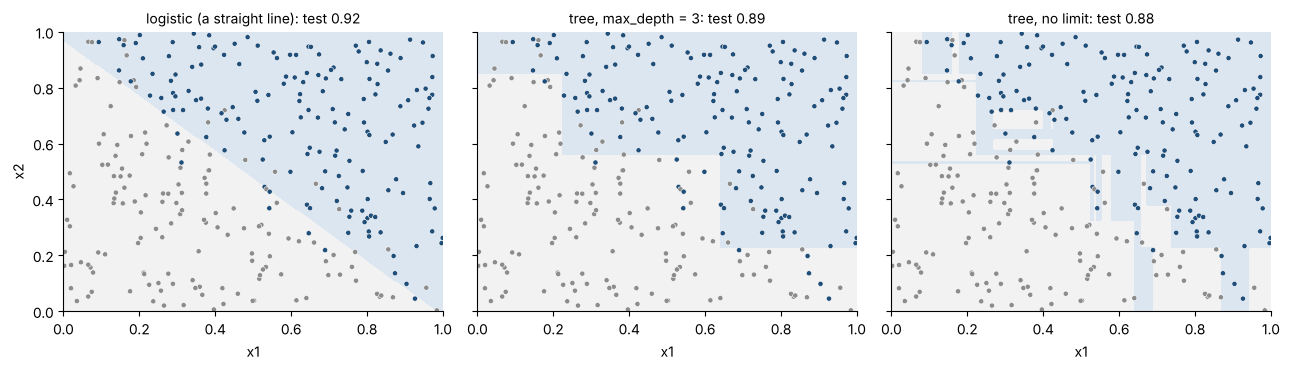

In [12]:
rng = np.random.default_rng(1)
Xd = rng.uniform(0, 1, size=(400, 2))
yd = ((Xd[:, 0] + Xd[:, 1] + rng.normal(0, 0.08, 400)) > 1).astype(int)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.25, random_state=42, stratify=yd)
from sklearn.linear_model import LogisticRegression
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
models = [("logistic (a straight line)", LogisticRegression()), ("tree, max_depth = 3", DecisionTreeClassifier(max_depth=3, random_state=0)), ("tree, no limit", DecisionTreeClassifier(random_state=0))]
for ax, (name, m) in zip(axes, models):
    m.fit(Xd_train, yd_train)
    xx, yy = np.meshgrid(np.linspace(0, 1, 250), np.linspace(0, 1, 250))
    zone = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zone, levels=[-0.5, 0.5, 1.5], colors=["#F2F2F2", "#DCE6F1"])
    ax.scatter(Xd_train[:, 0], Xd_train[:, 1], c=np.where(yd_train == 1, BLUE, GRAY), s=14, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{name}: test {m.score(Xd_test, yd_test):.2f}", fontsize=10); ax.set_xlabel("x1")
axes[0].set_ylabel("x2")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `rng.uniform(0, 1, size=(400, 2))`: 400 điểm với hai tọa độ ngẫu nhiên đều trong khoảng 0 đến 1.
- `yd = ((Xd[:, 0] + Xd[:, 1] + rng.normal(0, 0.08, 400)) > 1).astype(int)`: nhãn 1 nếu tổng hai tọa độ **cộng nhiễu nhỏ** vượt 1: ranh giới thật là đường chéo `x1 + x2 = 1`, hơi nhòe.
- `models = [(name, model), ...]`: ba ứng viên: logistic (đường thẳng), cây ba tầng, cây không giới hạn.
- `np.c_[xx.ravel(), yy.ravel()]`: (đã học ở C1) ghép lưới điểm thành bảng hai cột; ở đây dữ liệu là mảng numpy nên không cần tên cột.

**Cách đọc**

- **Con số:** logistic đạt **0,92**, cây ba tầng **0,89**, cây không giới hạn **0,88**.
- **Bức tranh:** đường chéo thật được logistic vẽ **một nét thẳng**; cây phải **xấp xỉ bằng các bậc thang vuông góc**. Cây ba tầng có vài bậc to (thô); cây không giới hạn có rất nhiều bậc nhỏ ôm sát điểm, *thuộc lòng nhiễu*, rìa răng cưa.
- **Ý nghĩa:** khi sự thật là **tổ hợp của nhiều cột** (tổng, hiệu, tỉ số), cây tốn nhiều câu hỏi để mô phỏng; mô hình tuyến tính thì được miễn phí. Ngược lại với vòng tròn đồng tâm (C1), cây thắng đẹp và logistic bó tay. *Không mô hình nào thắng ở mọi nơi*: mỗi cái hợp với hình dáng ranh giới riêng.

So lần cuối trên bộ ung thư, đo bằng kiểm định chéo lặp trên tập học:

In [13]:
from sklearn.pipeline import make_pipeline
final = {
    "lazy (most frequent)": __import__("sklearn.dummy", fromlist=["DummyClassifier"]).DummyClassifier(strategy="most_frequent"),
    "tree, max_depth = 3": DecisionTreeClassifier(max_depth=3, random_state=0),
    "tree, min_samples_leaf = 5": DecisionTreeClassifier(min_samples_leaf=5, random_state=0),
    "logistic (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}
board = {name: cross_val_score(m, X_train, y_train, cv=cv) for name, m in final.items()}
print(pd.DataFrame({n: {"CV mean": s.mean(), "CV std": s.std()} for n, s in board.items()}).T.round(3).to_string())

                            CV mean  CV std
lazy (most frequent)          0.627   0.005
tree, max_depth = 3           0.927   0.025
tree, min_samples_leaf = 5    0.929   0.024
logistic (scaled)             0.975   0.016


**Giải thích từng dòng**

- `__import__("sklearn.dummy", fromlist=["DummyClassifier"]).DummyClassifier(...)`: cách viết gọn để gọi `DummyClassifier` ngay trong từ điển mà không phải thêm một dòng `import`: máy lười đã gặp ở A6 và C2.
- `board = {name: cross_val_score(m, X_train, y_train, cv=cv) for name, m in final.items()}`: (đã học) mỗi ứng viên 50 điểm.

**Cách đọc:** máy lười 0,627; cây ba tầng **0,927**; cây `min_samples_leaf = 5` **0,929**; logistic **0,975**. Cây hơn mốc lười rất xa, nhưng **kém logistic khoảng 0,05**, lớn hơn nhiều so với độ lệch chuẩn (dưới 0,03): đây là chênh lệch có nghĩa.

## Phán quyết và bài học nghề

**Phán quyết cho chị Hạnh.** Nếu chị cần **tờ quy tắc đọc được** thì dùng cây nông (độ sâu 3, bảy lá, độ đúng khoảng 0,93); hai cột đầu tiên cây hỏi, `worst perimeter` rồi `worst concave points`, dễ đưa lên bảng. Nếu chị cần **độ đúng cao nhất**, logistic có chuẩn hóa (khoảng 0,975) hơn rõ ràng; và các mô hình ensemble ở phần E còn hơn nữa. Hai mục tiêu (dễ đọc và chính xác) *không phải lúc nào cũng cùng đạt*: đây là sự đánh đổi chị cần quyết.

**Bài học nghề.**

1. **Cây = chuỗi câu hỏi có/không**, đọc được thành tờ quy tắc; lá cho kết luận, `predict_proba` là tỉ lệ nhóm trong lá.
2. **Máy chọn câu hỏi bằng Gini:** thử mọi cột, mọi ngưỡng, chọn cái làm hai nhóm con thuần nhất; lặp lại (tham lam).
3. **Không cần chuẩn hóa**, nhận cả cột hỗn hợp; ranh giới là các hình chữ nhật.
4. **Cây không giới hạn thuộc lòng**: ghìm bằng `max_depth`, `min_samples_leaf`, `ccp_alpha`; chọn cây nhỏ nhất đạt cao nguyên.
5. **Bấp bênh:** dữ liệu đổi nhẹ thì cây đổi nhiều; nền tảng của ensemble.
6. **`feature_importances_`** không phải nhân quả và bị chia lẻ giữa các cột tương quan.

**Một điều thành thật:** cây "đọc được" không có nghĩa là cây "đúng". Một tờ quy tắc đẹp từ một tập học nhỏ vẫn có thể là *ảo giác của mẫu*. Dán lên tường thì phải đi kèm *"độ tin cậy khoảng bao nhiêu"* và lịch cập nhật.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Cây = chuỗi câu hỏi có/không; gốc, nút, nhánh, lá; đọc `export_text` hoặc `plot_tree` là đọc được tờ quy tắc. |
| 2 | Máy chọn câu hỏi làm Gini trung bình có trọng số thấp nhất, thử mọi cột và ngưỡng, lặp lại (tham lam). |
| 3 | Cây không cần chuẩn hóa; `feature_importances_` là mức dùng, không phải nhân quả. |
| 4 | Cây không giới hạn thuộc lòng; ghìm bằng `max_depth`, `min_samples_leaf`, `ccp_alpha`. |
| 5 | Cây bấp bênh (phương sai cao): đổi vài ca, đổi cả cây. |
| 6 | Ranh giới của cây là hình chữ nhật: yếu với ranh giới chéo; đổi lại dễ đọc. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Câu hỏi có/không ở mỗi bước | nút (node), ngưỡng chia | `tree_.feature`, `tree_.threshold` |
| Nơi dừng lại và kết luận | lá (leaf) | `get_n_leaves()` |
| Số tầng câu hỏi | độ sâu (depth) | `max_depth`, `get_depth()` |
| Mức lẫn lộn của một nhóm | chỉ số Gini | `1 - p**2 - (1 - p)**2` |
| Mỗi lá phải có ít nhất bấy nhiêu ca | kích thước lá tối thiểu | `min_samples_leaf` |
| Cắt bớt nhánh ít lợi | cắt tỉa chi phí-độ phức tạp | `ccp_alpha` |
| Cột nào được dùng nhiều | độ quan trọng của cột | `feature_importances_` |
| In cây ra chữ hoặc hình | xuất cây | `export_text`, `plot_tree` |
| Dữ liệu đổi nhẹ, cây đổi nhiều | phương sai cao | bốc lại có hoàn lại |

**Thử thách tự làm**

1. Ở chặng 1, đổi `max_depth` thành 3 rồi 4 và dùng `export_text`. Câu hỏi nào được thêm vào? Các lá nào vẫn còn lẫn nhiều nhất?
2. Ở chặng 4, thêm `min_samples_leaf = 2` và `min_samples_leaf = 10` vào bảng. Số lá và điểm kiểm định chéo thế nào?
3. Kể chuyện với dữ liệu khác: dùng `load_wine` (C3). Học cây ba tầng, vẽ `plot_tree`, đọc ba câu hỏi đầu và đối chiếu với các cột mà k-NN dùng hiệu quả nhất.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Đọc một cây thành tờ quy tắc (nút, nhánh, lá, `value`).
- [ ] Giải thích Gini và cách máy chọn ngưỡng ở một nút.
- [ ] Biết cây không cần chuẩn hóa và `NaN` phụ thuộc phiên bản sklearn.
- [ ] Ghìm cây bằng `max_depth` hoặc `min_samples_leaf` bằng kiểm định chéo.
- [ ] Giải thích vì sao cây bấp bênh và liên hệ đến ensemble.
- [ ] Biết khi nào cây thua mô hình tuyến tính (ranh giới chéo).

## Phần thưởng (Tip pro): Cây hồi quy: cùng ý tưởng, đổi Gini thành sai số bình phương


Với bài **hồi quy** (đoán một con số), dùng `DecisionTreeRegressor`: máy cũng hỏi câu có/không, nhưng thay Gini bằng **tổng bình phương sai lệch** (như B1) trong từng nhóm con; **lá dự đoán bằng trung bình** `y` của các ca trong lá. Vì vậy đường dự đoán là **bậc thang**, giống k-NN hồi quy (C3). Thử với bài chị Hạnh ở B1:

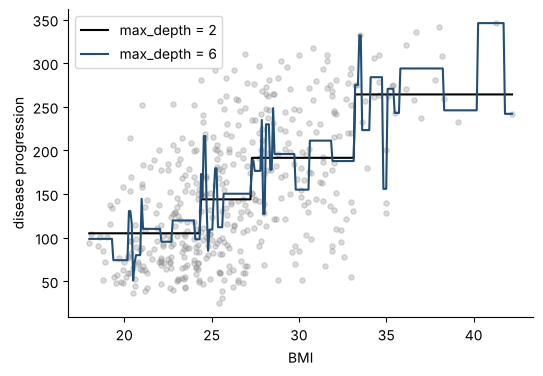

In [14]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.datasets import load_diabetes
d = load_diabetes(as_frame=True, scaled=False).frame
bx, by = d[["bmi"]], d["target"]
gx = pd.DataFrame({"bmi": np.linspace(bx["bmi"].min(), bx["bmi"].max(), 300)})
plt.scatter(bx["bmi"], by, color=GRAY, alpha=0.3, s=14)
for depth, c in [(2, "black"), (6, BLUE)]:
    plt.plot(gx["bmi"], DecisionTreeRegressor(max_depth=depth, random_state=0).fit(bx, by).predict(gx), color=c, label=f"max_depth = {depth}")
plt.xlabel("BMI"); plt.ylabel("disease progression"); plt.legend(); plt.show()

**Giải thích từng dòng**

- `DecisionTreeRegressor(max_depth=depth, random_state=0)`: cây hồi quy: mọi núm vặn (`max_depth`, `min_samples_leaf`...) giữ nguyên ý nghĩa.
- `for depth, c in [(2, "black"), (6, BLUE)]:`: hai đường: cây nông (4 bậc, thô) và cây sâu (nhiều bậc, ôm sát nhiễu).